# GRPO on the production model: Qwen2.5-1.5B SFT + age-conditioned readability (single T4)

Follow-up to `grpo_age_alignment.ipynb` (TinyLlama). Same rewards, same GRPO setup, three changes:

- **Start**: the Qwen SFT adapter (`sft/sft_lora_qwen_rag.ipynb`, config `E_alpha64`) merged into
  Qwen2.5-1.5B-Instruct; GRPO trains a new LoRA on top, KL to the SFT model
- **Training prompts = serving prompts**: the v3 rows (`scripts/build_rag_sft.py`), where knowledge questions carry
  the agent's "Facts that may help" passages, so RL does not drift from the format the agent sends
- **Evaluation at the deployed sampling**: temperature 0.3, 160 new tokens (the agent's settings), for base, SFT and
  SFT+GRPO; nothing is reused from the SFT notebook, which sampled at 0.8 / 128 tokens. Rollouts during training
  stay at 0.9: GRPO needs different samples in a group to learn from

Why on Qwen: Qwen SFT is better than TinyLlama SFT for ages 14-18 but worse for 4-9 (its base writes harder text),
which is the gap the readability reward targets.

After this notebook: check hallucination at temperature 0.3 on the 30 test questions (`eval/README.md`) before
adopting the GRPO adapter; RL on readability can trade facts for simpler words.

**Setup**: `data/children_sft_v3_rag/{train,validation}.jsonl` on Drive at `DATA_DIR` (as for the SFT notebook).
Every run is a separate process and writes to Drive; finished runs are skipped on re-run.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U vllm trl peft sentence-transformers textstat evaluate bert_score rouge_score
!pip uninstall -y -q torchao   # old Colab torchao breaks new PEFT at import time
# Installing vLLM can replace torch: restart the session once (Runtime -> Restart session), then run from the next cell

name, memory.total [MiB]
Tesla T4, 15360 MiB
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 2

## 0. Config

In [2]:
import os, json, time, gc, random, subprocess, sys
import numpy as np
import torch

BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
DATASET = "yxpan/children_sft_dataset_v2"   # hold-out (test split, no facts), same as the SFT notebook
DATA_DIR = "/content/drive/MyDrive/llm_sft_data/children_sft_v3_rag"   # training prompts with facts

SFT_DIR = "/content/drive/MyDrive/llm_sft_runs/sft_lora_qwen_rag"   # output of sft/sft_lora_qwen_rag.ipynb
SFT_BEST = "E_alpha64"          # best of C / E by validation BERTScore in the Qwen SFT run
EXP_NAME = "grpo_qwen_rag"
SEED = 42

GRPO = dict(
    lr=5e-5, lora_r=16, lora_alpha=32,          # first v2 run: lr 2e-5, beta 0.04
    lora_targets=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    num_generations=4,          # completions per prompt (the GRPO group)
    batch_completions=8,        # completions per device batch (= 2 prompts x 4)
    grad_accum=2,               # -> 16 completions (4 prompts) per optimizer step
    max_completion_length=160, temperature=0.9, beta=0.01,
    reward_weights=[1.0, 0.5, 0.3],   # readability, relevance, format
    vllm_gpu_mem=0.3, vllm_max_len=1024,        # prompts with facts are ~500 tokens + 160 new
    # T4 has no bf16: training runs in fp16. If the loss or KL turns NaN, lower lr to 2e-5 first
)
BENCH = dict(n_prompts=64, hf_batch_prompts=8, vllm_gpu_mem=0.5)
BENCH_STEPS = 20                 # GRPO steps per engine for the end-to-end speed comparison
RUN_SPEED_BENCH = False          # already measured on T4 in grpo_v1 (8.1x rollout, 2.2x step); True to re-measure
TRAIN_STEPS = 250
TRAIN_MODE = "vllm"              # engine for the main run; set to "hf" if vLLM does not work on this runtime

# evaluation at the agent's sampling (sprout/config.py): temperature 0.3, 160 new tokens
GEN_KWARGS = dict(max_new_tokens=160, do_sample=True, temperature=0.3, top_p=0.9, top_k=30, repetition_penalty=1.05)
GEN_BATCH = 16
N_HOLDOUT = 600
AGE_SWEEP_N = 40                 # inputs for the age-sensitivity sweep (each generated at all 5 ages)
AGES = ["0-3", "4-6", "7-9", "10-13", "14-18"]

In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = f"/content/drive/MyDrive/llm_rl_runs/{EXP_NAME}"
    WORK_DIR = "/content/rl_work"
except ImportError:
    OUT_DIR = os.path.join(os.environ.get("OUT_ROOT", os.path.expanduser("~/llm_rl_runs")), EXP_NAME)
    WORK_DIR = os.path.abspath("rl_work")
    SFT_DIR = os.environ.get("SFT_DIR", SFT_DIR)
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(WORK_DIR, exist_ok=True)
SFT_MERGED = os.path.join(WORK_DIR, "sft_merged")       # local disk: vLLM loads the model from this path
RL_CONFIG = os.path.join(OUT_DIR, "rl_config.json")

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU"
if SFT_BEST is None:
    SFT_BEST = json.load(open(f"{SFT_DIR}/best_config.json"))["best"]
print("SFT starting point:", SFT_BEST)
assert os.path.exists(f"{SFT_DIR}/{SFT_BEST}/adapter/adapter_model.safetensors"), \
    "SFT adapter not found: run sft_lora_experiments.ipynb first"
import transformers, trl, peft
transformers.logging.set_verbosity_error()
ENV = dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__, transformers=transformers.__version__,
           trl=trl.__version__, peft=peft.__version__)
try:
    import vllm; ENV["vllm"] = vllm.__version__
except Exception as e:
    ENV["vllm"] = f"not importable: {e}"
print(ENV); print("Outputs ->", OUT_DIR)

Mounted at /content/drive
SFT starting point: E_alpha64
{'gpu': 'Tesla T4', 'torch': '2.14.0+cu130', 'transformers': '5.22.1', 'trl': '1.18.2', 'peft': '0.22.0', 'vllm': '0.34.0'}
Outputs -> /content/drive/MyDrive/llm_rl_runs/grpo_qwen_rag


## 1. Merge the SFT adapter (fp16, so vLLM on T4 does not try bf16)

In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

if not os.path.exists(os.path.join(SFT_MERGED, "config.json")):
    base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16)
    merged = PeftModel.from_pretrained(base, f"{SFT_DIR}/{SFT_BEST}/adapter").merge_and_unload()
    merged.save_pretrained(SFT_MERGED)
    AutoTokenizer.from_pretrained(BASE_MODEL).save_pretrained(SFT_MERGED)
    del base, merged; gc.collect()
merged_cfg = json.load(open(os.path.join(SFT_MERGED, "config.json")))
print("merged model dtype:", merged_cfg.get("torch_dtype", merged_cfg.get("dtype")))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

merged model dtype: float16


## 2. Data, reward targets, and the reward functions

**Readability reward: distance to the row's reference FKGL, dense.** Two earlier designs, and what each run showed:

- **v1, age-group band** (FKGL inside the 25th-75th percentile of the age group's training references): not the
  quantity the evaluation measures (distance to each row's own reference), and on v1 GRPO moved the reward but barely
  moved the hold-out metric. On v2 the SFT failure analysis also showed 10-13 and 14-18 answers are too simple
  (median FKGL 0.9 below the reference) while their median FKGL (8.4 and 9.9) sits inside the band, so the band gives
  them full credit and no push upward.
- **first v2 run, flat within 2 grades** (1 when the distance is at most 2, falling to 0 at 5): the right target, and
  the teen groups improved, but about 80% of samples already scored 1, so most GRPO groups had no readability
  difference between their samples. The learning signal came mostly from the relevance reward; the readability
  reward stayed flat during training and KL to SFT ended near 0.004.

Now: reward = max(0, 1 - d / 5), with d the distance between the answer's FKGL and the row's reference FKGL. Every
step closer to the target scores higher, so the samples in a group differ in readability reward and GRPO has a
signal to learn from. The evaluation still reports the share within 2 grade levels. The v2 data pipeline already
removed references with outlier FKGL for their age group, which limits noise in the per-row targets.

Bands and length caps still come from the **training** references only, per age group: bands are kept for
reporting, the length cap is used by the format reward.


In [6]:
import textstat
from datasets import load_dataset

dsd = load_dataset(DATASET)
if {"train", "validation", "test"} <= set(dsd.keys()):   # v2: fixed stratified splits (same as the SFT notebook)
    train_ds, eval_ds, holdout_ds = dsd["train"], dsd["validation"], dsd["test"]
else:                                                  # v1: a single split, cut by row index
    ds = dsd["train"]
    train_ds, eval_ds = ds.select(range(500)), ds.select(range(500, 600))
    holdout_ds = ds.select(range(600, min(600 + N_HOLDOUT, len(ds))))
TRAIN_ROWS, EVAL_ROWS, HOLDOUT_ROWS = list(train_ds), list(eval_ds), list(holdout_ds)

def system_prompt(age):
    return (f"You are talking to a child aged {age}. "
            f"Generate a friendly response with age-appropriate knowledge.")

def prompt_messages(age, instruction):
    return [{"role": "system", "content": system_prompt(age)}, {"role": "user", "content": instruction}]

def fkgl(t):
    return float(textstat.flesch_kincaid_grade(t)) if t.strip() else float("nan")

band, max_words = {}, {}
for age in AGES:
    refs = [r["response"] for r in TRAIN_ROWS if r["age"] == age]
    if len(refs) < 20:
        print(f"{age}: only {len(refs)} training rows, no band (this age gets no readability reward)")
        continue
    f = np.array([fkgl(t) for t in refs])
    band[age] = [round(float(np.nanpercentile(f, 25)), 2), round(float(np.nanpercentile(f, 75)), 2)]
    max_words[age] = int(1.5 * np.percentile([len(t.split()) for t in refs], 75))
print("FKGL band per age:", band); print("length cap (words):", max_words)

# training prompts: the v3 rows carry the exact serving prompt (facts for retrieved knowledge questions)
V3_TRAIN = [json.loads(l) for l in open(f"{DATA_DIR}/train.jsonl", encoding="utf-8")]
assert [r["instruction"] for r in V3_TRAIN] == [r["instruction"] for r in TRAIN_ROWS], "v3 rows must match the v2 train split"
print("training prompts with facts:", sum(r["with_facts"] for r in V3_TRAIN), "of", len(V3_TRAIN))
train_file = os.path.join(OUT_DIR, "rl_train.jsonl")
with open(train_file, "w") as f:
    for r in V3_TRAIN:
        ref_fkgl = fkgl(r["response"])
        if r["age"] in band and not np.isnan(ref_fkgl):
            f.write(json.dumps(dict(prompt=r["messages"][:-1], age=r["age"],
                                    reference=r["response"], ref_fkgl=ref_fkgl)) + "\n")

RL_CFG = dict(sft_merged=SFT_MERGED, train_file=train_file, out_dir=OUT_DIR, work_dir=WORK_DIR, seed=SEED,
              fkgl_band=band, max_words=max_words, fkgl_zero=5.0,
              embed_model="sentence-transformers/all-MiniLM-L6-v2", grpo=GRPO, bench=BENCH, env=ENV)
json.dump(RL_CFG, open(RL_CONFIG, "w"), indent=1)
os.environ["RL_CONFIG"] = RL_CONFIG

README.md:   0%|          | 0.00/807 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  183kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 33.6kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  106kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/700 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/393 [00:00<?, ? examples/s]

FKGL band per age: {'0-3': [1.09, 4.06], '4-6': [1.85, 4.64], '7-9': [5.93, 8.12], '10-13': [7.59, 10.0], '14-18': [9.55, 13.26]}
length cap (words): {'0-3': 42, '4-6': 55, '7-9': 124, '10-13': 141, '14-18': 169}
training prompts with facts: 254 of 700


In [7]:
RL_REWARDS = '"""Reward functions for GRPO: readability relative to the reference, relevance to the reference, format.\nThe config path is read from the RL_CONFIG environment variable."""\nimport json\nimport os\n\nimport numpy as np\nimport textstat\n\n_CFG = None\n_EMB = None\n\n\ndef cfg():\n    global _CFG\n    if _CFG is None:\n        with open(os.environ["RL_CONFIG"]) as f:\n            _CFG = json.load(f)\n    return _CFG\n\n\ndef _text(c):\n    # conversational completions look like [{"role": "assistant", "content": "..."}]\n    if isinstance(c, list):\n        return c[0]["content"] if c else ""\n    return c or ""\n\n\ndef fkgl(text):\n    return float(textstat.flesch_kincaid_grade(text)) if text.strip() else float("nan")\n\n\ndef readability_reward(completions, ref_fkgl, **kwargs):\n    """Dense reward on the distance d between the answer\'s FKGL and this row\'s reference FKGL:\n    1 - d / fkgl_zero, floored at 0. Every grade level closer to the target scores higher."""\n    zero = cfg()["fkgl_zero"]\n    out = []\n    for c, target in zip(completions, ref_fkgl):\n        g = fkgl(_text(c))\n        if target is None or np.isnan(g) or np.isnan(target):\n            out.append(0.0)\n            continue\n        out.append(float(max(0.0, 1.0 - abs(g - target) / zero)))\n    return out\n\n\ndef get_embedder():\n    global _EMB\n    if _EMB is None:\n        import torch\n        from sentence_transformers import SentenceTransformer\n        _EMB = SentenceTransformer(cfg()["embed_model"], device="cuda" if torch.cuda.is_available() else "cpu")\n    return _EMB\n\n\ndef relevance_reward(completions, reference, **kwargs):\n    """Cosine similarity to the reference answer, so short empty answers can\'t farm the readability reward."""\n    texts = [_text(c) for c in completions]\n    emb = get_embedder()\n    a = emb.encode(texts, normalize_embeddings=True, convert_to_numpy=True)\n    b = emb.encode(list(reference), normalize_embeddings=True, convert_to_numpy=True)\n    sims = (a * b).sum(axis=1)\n    return [float(max(0.0, s)) if t.strip() else 0.0 for s, t in zip(sims, texts)]\n\n\ndef distinct_ratio(text, n=3):\n    w = text.lower().split()\n    grams = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]\n    return len(set(grams)) / len(grams) if grams else 1.0\n\n\ndef format_reward(completions, age, **kwargs):\n    """Penalize empty answers, answers longer than the age group\'s length cap, and repetition loops."""\n    out = []\n    for c, a in zip(completions, age):\n        t = _text(c).strip()\n        if not t:\n            out.append(0.0)\n            continue\n        r = 1.0\n        n, cap = len(t.split()), cfg()["max_words"].get(a, 200)\n        if n > cap:\n            r -= min(1.0, (n - cap) / cap)\n        if distinct_ratio(t) < 0.6:\n            r -= 0.5\n        out.append(max(0.0, r))\n    return out\n\n\nREWARD_FUNCS = [readability_reward, relevance_reward, format_reward]\n'
GRPO_TRAIN = '"""One GRPO run per process (so HF and vLLM runs never share GPU state).\npython grpo_train.py --config rl_config.json --mode hf|vllm --steps N --name RUN [--save]"""\nimport argparse\nimport json\nimport os\nimport sys\nimport time\n\n\ndef main(argv=None):\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--config", required=True)\n    ap.add_argument("--mode", choices=["hf", "vllm"], required=True)\n    ap.add_argument("--steps", type=int, required=True)\n    ap.add_argument("--name", required=True)\n    ap.add_argument("--save", action="store_true", help="save the LoRA adapter")\n    ap.add_argument("--device", default="cuda", help="\'cpu\' only for smoke tests")\n    a = ap.parse_args(argv)\n\n    os.environ["RL_CONFIG"] = a.config\n    cfg = json.load(open(a.config))\n    run_dir = os.path.join(cfg["out_dir"], "runs", a.name)\n    adapter_file = os.path.join(run_dir, "adapter", "adapter_model.safetensors")\n    if os.path.exists(os.path.join(run_dir, "summary.json")) and (not a.save or os.path.exists(adapter_file)):\n        print(f"[{a.name}] already done, skipping")\n        return\n    os.makedirs(run_dir, exist_ok=True)\n\n    import torch\n    from datasets import load_dataset\n    from peft import LoraConfig\n    from transformers import AutoModelForCausalLM, AutoTokenizer\n    from trl import GRPOConfig, GRPOTrainer\n    sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))\n    import rl_rewards\n\n    cpu = a.device == "cpu"\n    g = cfg["grpo"]\n    tok = AutoTokenizer.from_pretrained(cfg["sft_merged"])\n    if tok.pad_token is None:\n        tok.pad_token = tok.eos_token\n    model = AutoModelForCausalLM.from_pretrained(cfg["sft_merged"], torch_dtype=torch.float32 if cpu else torch.float16)\n    train = load_dataset("json", data_files=cfg["train_file"])["train"]\n\n    args = GRPOConfig(\n        output_dir=os.path.join(cfg["work_dir"], a.name), max_steps=a.steps, learning_rate=g["lr"],\n        per_device_train_batch_size=g["batch_completions"], num_generations=g["num_generations"],\n        gradient_accumulation_steps=g["grad_accum"], max_completion_length=g["max_completion_length"],\n        temperature=g["temperature"], beta=g["beta"], reward_weights=g["reward_weights"],\n        logging_steps=1, save_strategy="no", report_to="none", seed=cfg["seed"],\n        fp16=not cpu, bf16=False, use_cpu=cpu,\n        use_vllm=a.mode == "vllm", vllm_mode="colocate", vllm_gpu_memory_utilization=g["vllm_gpu_mem"],\n        vllm_max_model_length=g["vllm_max_len"],\n    )\n    peft_cfg = LoraConfig(r=g["lora_r"], lora_alpha=g["lora_alpha"], lora_dropout=0.05,\n                          target_modules=g["lora_targets"], bias="none", task_type="CAUSAL_LM")\n    trainer = GRPOTrainer(model=model, reward_funcs=rl_rewards.REWARD_FUNCS, args=args, train_dataset=train,\n                          processing_class=tok, peft_config=peft_cfg)\n    if not cpu:\n        torch.cuda.reset_peak_memory_stats()\n    t0 = time.time()\n    trainer.train()\n    wall = time.time() - t0\n\n    json.dump(trainer.state.log_history, open(os.path.join(run_dir, "log_history.json"), "w"), indent=1)\n    if a.save:\n        trainer.model.save_pretrained(os.path.join(run_dir, "adapter"))\n        tok.save_pretrained(os.path.join(run_dir, "adapter"))\n    summary = dict(name=a.name, mode=a.mode, steps=a.steps, wall_s=round(wall, 1),\n                   gpu=None if cpu else torch.cuda.get_device_name(0),\n                   peak_torch_mem_gb=None if cpu else round(torch.cuda.max_memory_allocated() / 1e9, 2))\n    json.dump(summary, open(os.path.join(run_dir, "summary.json"), "w"), indent=1)\n    print(summary)\n\n\nif __name__ == "__main__":\n    main()\n'
ROLLOUT_BENCH = '"""Rollout throughput: HF generate vs vLLM on the same prompts with the same sampling settings.\nOne engine per process. python rollout_bench.py --config rl_config.json --engine hf|vllm"""\nimport argparse\nimport json\nimport os\nimport time\n\n\ndef main(argv=None):\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--config", required=True)\n    ap.add_argument("--engine", choices=["hf", "vllm"], required=True)\n    a = ap.parse_args(argv)\n    cfg = json.load(open(a.config))\n    out_path = os.path.join(cfg["out_dir"], f"rollout_bench_{a.engine}.json")\n    if os.path.exists(out_path):\n        print("already done:", json.load(open(out_path)))\n        return\n\n    import torch\n    from transformers import AutoTokenizer\n    b, g = cfg["bench"], cfg["grpo"]\n    tok = AutoTokenizer.from_pretrained(cfg["sft_merged"])\n    if tok.pad_token is None:\n        tok.pad_token = tok.eos_token\n    rows = [json.loads(l) for l in open(cfg["train_file"])][: b["n_prompts"]]\n    texts = [tok.apply_chat_template(r["prompt"], tokenize=False, add_generation_prompt=True) for r in rows]\n    n, max_new, temp = g["num_generations"], g["max_completion_length"], g["temperature"]\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n\n    if a.engine == "hf":\n        from transformers import AutoModelForCausalLM\n        model = AutoModelForCausalLM.from_pretrained(\n            cfg["sft_merged"], torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()\n        tok.padding_side = "left"\n\n        @torch.no_grad()\n        def run(batch_texts):\n            tokens = 0\n            for i in range(0, len(batch_texts), b["hf_batch_prompts"]):\n                enc = tok(batch_texts[i:i + b["hf_batch_prompts"]], return_tensors="pt", padding=True,\n                          add_special_tokens=False).to(device)\n                out = model.generate(**enc, do_sample=True, temperature=temp, max_new_tokens=max_new,\n                                     num_return_sequences=n, pad_token_id=tok.pad_token_id)\n                gen = out[:, enc["input_ids"].shape[1]:]\n                tokens += int((gen != tok.pad_token_id).sum())\n            return tokens\n\n        run(texts[:2])  # warmup\n        if device == "cuda":\n            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()\n        t0 = time.time(); tokens = run(texts)\n        if device == "cuda":\n            torch.cuda.synchronize()\n        secs = time.time() - t0\n        mem = round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else None\n    else:\n        from vllm import LLM, SamplingParams\n        llm = LLM(model=cfg["sft_merged"], dtype="float16", gpu_memory_utilization=b["vllm_gpu_mem"],\n                  max_model_len=g["vllm_max_len"], seed=cfg["seed"])\n        sp = SamplingParams(n=n, temperature=temp, max_tokens=max_new, seed=cfg["seed"])\n        llm.generate(texts[:2], sp)  # warmup\n        t0 = time.time(); outs = llm.generate(texts, sp); secs = time.time() - t0\n        tokens = sum(len(o.token_ids) for r in outs for o in r.outputs)\n        mem = None  # vLLM pre-allocates gpu_memory_utilization of the GPU; peak torch memory is not meaningful\n\n    res = dict(engine=a.engine, n_prompts=len(texts), completions=len(texts) * n, completion_tokens=tokens,\n               seconds=round(secs, 2), tokens_per_s=round(tokens / secs, 1),\n               completions_per_s=round(len(texts) * n / secs, 2), peak_torch_mem_gb=mem,\n               gpu=torch.cuda.get_device_name(0) if device == "cuda" else "cpu")\n    json.dump(res, open(out_path, "w"), indent=1)\n    print(res)\n\n\nif __name__ == "__main__":\n    main()\n'

for name, src in [("rl_rewards.py", RL_REWARDS), ("grpo_train.py", GRPO_TRAIN), ("rollout_bench.py", ROLLOUT_BENCH)]:
    with open(os.path.join(WORK_DIR, name), "w") as f:
        f.write(src)
sys.path.insert(0, WORK_DIR)
import importlib, rl_rewards
importlib.reload(rl_rewards)
print(os.listdir(WORK_DIR))

['rl_rewards.py', '__pycache__', 'grpo_train.py', 'rollout_bench.py', 'sft_merged']


## 3. Check the rewards before training

Reference answers score 1 on readability by construction (distance 0 to themselves), so the useful check is
SFT vs base: SFT should score clearly higher.
If not, the reward is measuring the wrong thing and must be fixed before any RL.

In [8]:
import pandas as pd

def load_preds(path):
    return [json.loads(l) for l in open(path)] if os.path.exists(path) else None

def score(texts, rows):
    as_completion = [[{"role": "assistant", "content": t}] for t in texts]
    ages, refs = [r["age"] for r in rows], [r["response"] if "response" in r else r["reference"] for r in rows]
    ref_fk = [fkgl(t) for t in refs]
    keep = [i for i, a in enumerate(ages) if a in band]
    sel = lambda xs: [xs[i] for i in keep]
    return dict(readability=np.mean(rl_rewards.readability_reward(sel(as_completion), sel(ref_fk))),
                relevance=np.mean(rl_rewards.relevance_reward(sel(as_completion), sel(refs))),
                format=np.mean(rl_rewards.format_reward(sel(as_completion), sel(ages))), n=len(keep))

checks = {"reference answers": score([r["response"] for r in EVAL_ROWS], EVAL_ROWS)}
for label, path in [("base model", f"{SFT_DIR}/base/eval_preds.jsonl"),
                    (f"SFT ({SFT_BEST})", f"{SFT_DIR}/{SFT_BEST}/eval_preds.jsonl")]:
    preds = load_preds(path)
    if preds:
        checks[label] = score([p["prediction"] for p in preds], [dict(age=p["age"], response=p["reference"]) for p in preds])
reward_check = pd.DataFrame(checks).T
reward_check["weighted"] = reward_check[["readability", "relevance", "format"]].values @ np.array(GRPO["reward_weights"])
display(reward_check.round(3))
reward_check.to_csv(f"{OUT_DIR}/reward_check.csv")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,readability,relevance,format,n,weighted
reference answers,1.000,1.000,0.955,100.0,1.786
base model,0.494,0.621,0.869,100.0,1.065
SFT (E_alpha64),0.638,0.680,0.976,100.0,1.270


## 4. vLLM vs HF generate: rollout throughput

Same 64 training prompts, 4 samples each, same temperature and max length. Each engine runs in its own process.

In [9]:
def run_script(*args):
    cmd = [sys.executable, os.path.join(WORK_DIR, args[0])] + list(args[1:])
    print(" ".join(cmd))
    p = subprocess.run(cmd, env=dict(os.environ, RL_CONFIG=RL_CONFIG), capture_output=True, text=True)
    print(p.stdout[-2000:])
    if p.returncode != 0:
        print(p.stderr[-4000:])
        raise RuntimeError(f"{args[0]} failed (exit {p.returncode})")

for engine in (["hf", "vllm"] if RUN_SPEED_BENCH else []):
    try:
        run_script("rollout_bench.py", "--config", RL_CONFIG, "--engine", engine)
    except RuntimeError as e:
        print(e)

## 5. vLLM vs HF generate: end-to-end GRPO step time

Same config, same seed, `BENCH_STEPS` steps each; only the generation engine changes.
The first 2 steps are dropped as warmup.

In [10]:
for mode in (["hf", "vllm"] if RUN_SPEED_BENCH else []):
    try:
        run_script("grpo_train.py", "--config", RL_CONFIG, "--mode", mode, "--steps", str(BENCH_STEPS),
                   "--name", f"bench_{mode}")
    except RuntimeError as e:
        print(e)

In [11]:
import matplotlib.pyplot as plt

if not RUN_SPEED_BENCH:
    print("Speed comparison skipped (RUN_SPEED_BENCH=False). T4 results: llm_rl_runs/grpo_v1/vllm_vs_hf_speed.csv")
else:
    def step_stats(name):
        p = f"{OUT_DIR}/runs/{name}/log_history.json"
        if not os.path.exists(p):
            return None
        hist = [h for h in json.load(open(p)) if "step_time" in h][2:]
        st = np.array([h["step_time"] for h in hist])
        length = np.array([h.get("completions/mean_length", np.nan) for h in hist])
        per_step = GRPO["batch_completions"] * GRPO["grad_accum"]
        return dict(step_time_s=st.mean(), step_time_std=st.std(), mean_completion_len=np.nanmean(length),
                    train_tokens_per_s=np.nanmean(per_step * length / st), steps_measured=len(st))

    rows = {}
    for engine in ["hf", "vllm"]:
        rb = f"{OUT_DIR}/rollout_bench_{engine}.json"
        r = json.load(open(rb)) if os.path.exists(rb) else {}
        s = step_stats(f"bench_{engine}") or {}
        rows[engine] = dict(rollout_tokens_per_s=r.get("tokens_per_s"), rollout_seconds=r.get("seconds"), **s)
    speed = pd.DataFrame(rows).T
    if {"hf", "vllm"} <= set(speed.index) and speed.notna().all().all():
        speed.loc["vllm speedup (x)"] = [speed.loc["vllm", c] / speed.loc["hf", c] if "per_s" in c else
                                         speed.loc["hf", c] / speed.loc["vllm", c] if c in ("rollout_seconds", "step_time_s") else np.nan
                                         for c in speed.columns]
    display(speed.round(2))
    speed.to_csv(f"{OUT_DIR}/vllm_vs_hf_speed.csv")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, col, title in [(axes[0], "rollout_tokens_per_s", "Rollout throughput (tokens/s)"),
                           (axes[1], "step_time_s", "GRPO step time (s)")]:
        if col in speed.columns:
            vals = speed.loc[[e for e in ["hf", "vllm"] if e in speed.index], col]
            ax.bar(vals.index, vals.values, color=["#888", "#3a7"]); ax.set_title(title)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vllm_vs_hf_speed.png", dpi=150); plt.show()

Speed comparison skipped (RUN_SPEED_BENCH=False). T4 results: llm_rl_runs/grpo_v1/vllm_vs_hf_speed.csv


## 6. Main GRPO run

In [12]:
# Runs in the background with a log on Drive: the browser can disconnect without stopping training,
# and the next cell shows progress. Re-run only the monitor cell after reconnecting.
import shlex
LOG = f"{OUT_DIR}/logs/grpo_main.log"
os.makedirs(os.path.dirname(LOG), exist_ok=True)
if os.path.exists(f"{OUT_DIR}/runs/grpo_main/summary.json"):
    print("grpo_main already finished")
else:
    cmd = (f"RL_CONFIG={shlex.quote(RL_CONFIG)} nohup {sys.executable} -u {WORK_DIR}/grpo_train.py "
           f"--config {shlex.quote(RL_CONFIG)} --mode {TRAIN_MODE} --steps {TRAIN_STEPS} --name grpo_main --save "
           f"> {shlex.quote(LOG)} 2>&1 &")
    os.system(cmd)
    print("started in background, log ->", LOG)

started in background, log -> /content/drive/MyDrive/llm_rl_runs/grpo_qwen_rag/logs/grpo_main.log


In [ ]:
import time, ast
def progress():
    lines = open(LOG).read().splitlines() if os.path.exists(LOG) else []
    steps = []
    for l in lines:
        if l.startswith("{'loss'"):
            try: steps.append(ast.literal_eval(l))
            except Exception: pass
    errs = [l for l in lines if "Error" in l or "Traceback" in l or "Killed" in l]
    ram = subprocess.run("free -g | awk '/Mem/{print $3\"/\"$2\" GB\"}'", shell=True, capture_output=True, text=True).stdout.strip()
    if steps:
        s, n = steps[-1], len(steps)
        avg_t = np.mean([float(x["step_time"]) for x in steps[-20:]])
        rd = np.mean([float(x["rewards/readability_reward/mean"]) for x in steps[-20:]])
        print(f"step {n}/{TRAIN_STEPS} | readability(last20) {rd:.3f} | reward {float(s['reward']):.3f} | "
              f"kl {float(s['kl']):.4f} | {avg_t:.1f}s/step | ETA {(TRAIN_STEPS - n) * avg_t / 60:.0f} min | RAM {ram}")
    else:
        print("no step logged yet (loading model / vLLM warmup) | RAM", ram, "|", (lines[-1][:150] if lines else ""))
    if errs: print("ERROR:", *errs[-3:], sep="\n")
    return os.path.exists(f"{OUT_DIR}/runs/grpo_main/summary.json")

while not progress():
    time.sleep(60)
print("done")

no step logged yet (loading model / vLLM warmup) | RAM 7/12 GB | 
no step logged yet (loading model / vLLM warmup) | RAM 8/12 GB | Generating train split: 700 examples [00:00, 61214.12 examples/s]
no step logged yet (loading model / vLLM warmup) | RAM 9/12 GB | 
no step logged yet (loading model / vLLM warmup) | RAM 9/12 GB | [rank0]:W1123 01:17:34.964000 6018 torch/_inductor/utils.py:1806] Not enough SMs to use max_autotune_gemm mode
step 4/250 | readability(last20) 0.636 | reward 1.361 | kl 0.0007 | 10.6s/step | ETA 43 min | RAM 10/12 GB
step 9/250 | readability(last20) 0.564 | reward 0.886 | kl 0.0022 | 10.9s/step | ETA 44 min | RAM 10/12 GB
step 15/250 | readability(last20) 0.576 | reward 1.141 | kl 0.0086 | 10.5s/step | ETA 41 min | RAM 10/12 GB
step 20/250 | readability(last20) 0.590 | reward 1.118 | kl 0.0124 | 10.7s/step | ETA 41 min | RAM 10/12 GB
step 25/250 | readability(last20) 0.582 | reward 1.272 | kl 0.0142 | 10.9s/step | ETA 41 min | RAM 10/12 GB
step 31/250 | readabili

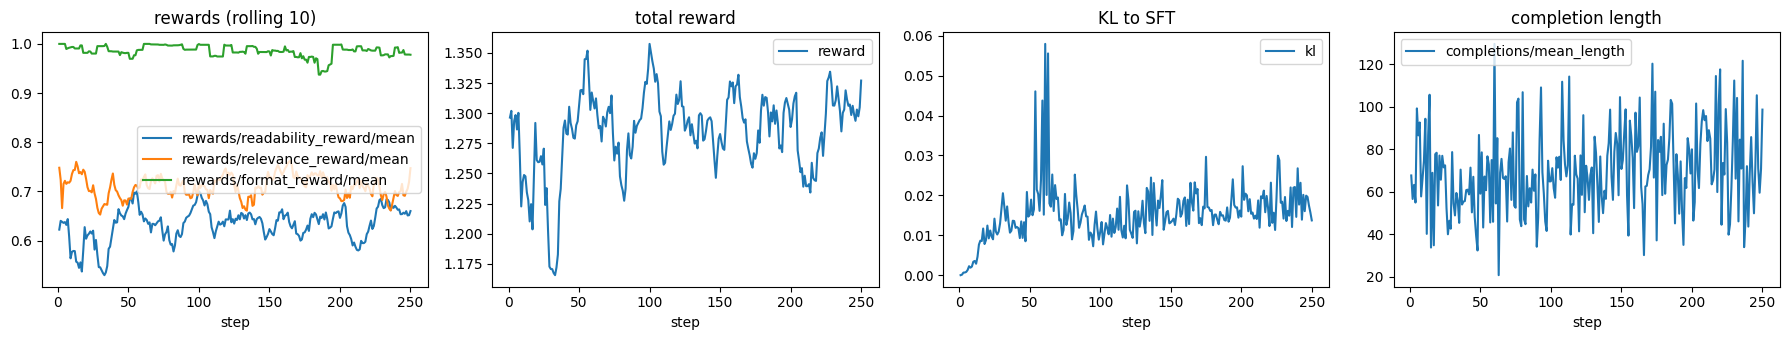

In [20]:
hist = json.load(open(f"{OUT_DIR}/runs/grpo_main/log_history.json"))
h = pd.DataFrame([x for x in hist if "reward" in x]).set_index("step")
reward_cols = [c for c in h.columns if c.startswith("rewards/") and c.endswith("/mean")]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
h[reward_cols].rolling(10, min_periods=1).mean().plot(ax=axes[0], title="rewards (rolling 10)")
h[["reward"]].rolling(10, min_periods=1).mean().plot(ax=axes[1], title="total reward")
if "kl" in h: h[["kl"]].plot(ax=axes[2], title="KL to SFT")
if "completions/mean_length" in h: h[["completions/mean_length"]].plot(ax=axes[3], title="completion length")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/grpo_training_curves.png", dpi=150); plt.show()

## 7. Evaluation: base vs SFT vs SFT+GRPO on the hold-out set

All three models answer at the deployed sampling (temperature 0.3, 160 new tokens), so the SFT numbers here
replace the SFT notebook's (0.8, 128 tokens) as the production numbers. Knowledge questions use `needs_knowledge` when the dataset has it
(v2), otherwise `intent == "scientific question"`.

In [21]:
import evaluate
rouge, bertscore = evaluate.load("rouge"), evaluate.load("bertscore")
tok = AutoTokenizer.from_pretrained(SFT_MERGED)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

@torch.no_grad()
def generate(model, prompts):
    tok.padding_side = "left"; torch.manual_seed(SEED); out_text = []
    for i in range(0, len(prompts), GEN_BATCH):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in prompts[i:i + GEN_BATCH]]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, **GEN_KWARGS, pad_token_id=tok.pad_token_id)
        out_text += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [t.strip() for t in out_text]

def text_metrics(preds, rows):
    refs = [r["response"] for r in rows]
    gap = np.abs(np.array([fkgl(p) for p in preds]) - np.array([fkgl(t) for t in refs]))
    return dict(n=len(rows),
                bert_f1=float(np.mean(bertscore.compute(predictions=preds, references=refs, lang="en", batch_size=32)["f1"])),
                rougeL=float(rouge.compute(predictions=preds, references=refs)["rougeL"]),
                fkgl_gap=float(np.nanmean(gap)), fkgl_within2=float(np.nanmean(gap <= 2)),
                mean_words=float(np.mean([len(p.split()) for p in preds])),
                distinct3=float(np.mean([rl_rewards.distinct_ratio(p) for p in preds])))

def is_knowledge(r):
    return bool(r["needs_knowledge"]) if "needs_knowledge" in r and r["needs_knowledge"] is not None \
        else r.get("intent") == "scientific question"

def load_model(name):
    m = AutoModelForCausalLM.from_pretrained(BASE_MODEL if name == "base" else SFT_MERGED, torch_dtype=torch.float16).to("cuda")
    if name == "sft+grpo":
        m = PeftModel.from_pretrained(m, f"{OUT_DIR}/runs/grpo_main/adapter")
    return m.eval()

holdout_prompts = [prompt_messages(r["age"], r["instruction"]) for r in HOLDOUT_ROWS]
PREDS = {}
for name, reuse in [("base", f"{OUT_DIR}/holdout_preds_base_t03.jsonl"), ("sft", f"{OUT_DIR}/holdout_preds_sft_t03.jsonl"),
                    ("sft+grpo", f"{OUT_DIR}/holdout_preds_grpo_t03.jsonl")]:     # all at temperature 0.3, 160 tokens
    old = load_preds(reuse)
    if old and len(old) == len(HOLDOUT_ROWS) and all(o["instruction"] == r["instruction"] for o, r in zip(old, HOLDOUT_ROWS)):
        PREDS[name] = [o["prediction"] for o in old]; print(name, "reused")
        continue
    m = load_model(name); PREDS[name] = generate(m, holdout_prompts); del m; gc.collect(); torch.cuda.empty_cache()
    if True:                                                     # keep every model's predictions (resume)
        with open(reuse, "w") as f:
            for p, r in zip(PREDS[name], HOLDOUT_ROWS):
                f.write(json.dumps(dict(age=r["age"], instruction=r["instruction"], reference=r["response"], prediction=p)) + "\n")

results = []
for name, preds in PREDS.items():
    groups = [("all", list(range(len(HOLDOUT_ROWS)))),
              ("knowledge", [i for i, r in enumerate(HOLDOUT_ROWS) if is_knowledge(r)]),
              ("non-knowledge", [i for i, r in enumerate(HOLDOUT_ROWS) if not is_knowledge(r)])]
    groups += [(f"age {a}", [i for i, r in enumerate(HOLDOUT_ROWS) if r["age"] == a]) for a in AGES]
    for gname, idx in groups:
        if len(idx) >= 10:
            results.append(dict(model=name, group=gname, **text_metrics([preds[i] for i in idx], [HOLDOUT_ROWS[i] for i in idx])))
EVAL = pd.DataFrame(results)
EVAL.to_csv(f"{OUT_DIR}/holdout_eval.csv", index=False)
display(EVAL.pivot(index="group", columns="model", values=["fkgl_within2", "fkgl_gap", "bert_f1"]).round(3))
display(EVAL.pivot(index="group", columns="model", values=["mean_words", "distinct3"]).round(2))

base reused
sft reused
sft+grpo reused


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

fkgl_within2                 fkgl_gap                 bert_f1  \
model                 base    sft sft+grpo     base    sft sft+grpo    base   
group                                                                         
age 0-3              0.610  0.662    0.662    2.048  1.923    1.617   0.874   
age 10-13            0.354  0.608    0.658    2.961  1.813    1.729   0.868   
age 14-18            0.088  0.538    0.512    4.369  2.069    2.081   0.859   
age 4-6              0.610  0.636    0.636    1.946  1.777    1.802   0.876   
age 7-9              0.538  0.688    0.625    2.029  1.657    1.791   0.874   
all                  0.438  0.626    0.618    2.680  1.848    1.805   0.870   
knowledge            0.349  0.609    0.589    3.031  1.873    1.915   0.874   
non-knowledge        0.522  0.642    0.647    2.344  1.824    1.700   0.867   

                               
model            sft sft+grpo  
group                          
age 0-3        0.895    0.898  
age 10-13      0.887    0.884  
age 14-18      0.883    0.883  
age 4-6        0.893    0.894  
age 7-9        0.894    0.896  
all            0.890    0.891  
knowledge      0.896    0.896  
non-knowledge  0.885    0.886

mean_words                 distinct3              
model               base    sft sft+grpo      base  sft sft+grpo
group                                                           
age 0-3            52.79  20.92    23.44      1.00  1.0      1.0
age 10-13         123.94  78.99    84.48      0.99  1.0      1.0
age 14-18         127.49  88.08    90.34      0.99  1.0      1.0
age 4-6            56.58  31.00    34.13      1.00  1.0      1.0
age 7-9           114.34  67.22    65.36      0.99  1.0      1.0
all                95.57  57.66    59.96      0.99  1.0      1.0
knowledge         107.37  55.82    59.19      0.99  1.0      1.0
non-knowledge      84.30  59.43    60.69      1.00  1.0      1.0

## 8. Age sensitivity: does the model follow the age the parent set?

`AGE_SWEEP_N` hold-out inputs, each generated at all 5 set ages. For each input, Spearman correlation between the
set age and the answer's FKGL (1 = always more advanced for older children).

,mean_spearman,share_rho_above_0_5
model,,
base,0.390,0.50
sft,0.767,0.85
sft+grpo,0.798,0.90


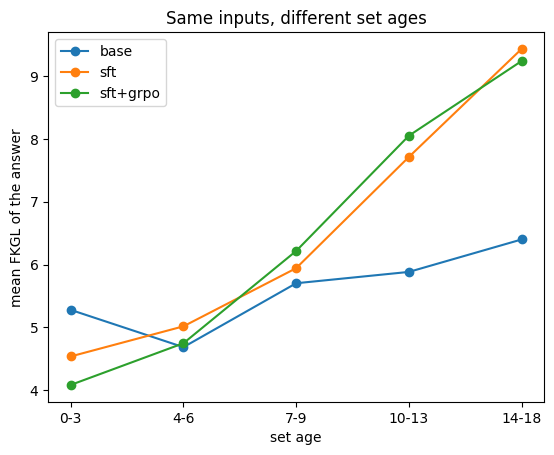

In [22]:
from scipy.stats import spearmanr

rng = random.Random(SEED)
sweep_rows = rng.sample(HOLDOUT_ROWS, min(AGE_SWEEP_N, len(HOLDOUT_ROWS)))
sweep_prompts = [prompt_messages(a, r["instruction"]) for r in sweep_rows for a in AGES]
sweep_path = f"{OUT_DIR}/age_sweep.json"
SWEEP = json.load(open(sweep_path)) if os.path.exists(sweep_path) else {}
for name in ["base", "sft", "sft+grpo"]:
    if name in SWEEP:
        continue
    m = load_model(name); SWEEP[name] = generate(m, sweep_prompts); del m; gc.collect(); torch.cuda.empty_cache()
    json.dump(SWEEP, open(sweep_path, "w"))

summary, curves = [], {}
for name, preds in SWEEP.items():
    f = np.array([fkgl(p) for p in preds]).reshape(len(sweep_rows), len(AGES))
    rhos = [spearmanr(range(len(AGES)), row).correlation for row in f]
    curves[name] = np.nanmean(f, axis=0)
    summary.append(dict(model=name, mean_spearman=float(np.nanmean(rhos)),
                        share_rho_above_0_5=float(np.nanmean(np.array(rhos) > 0.5))))
sweep_df = pd.DataFrame(summary).set_index("model")
display(sweep_df.round(3)); sweep_df.to_csv(f"{OUT_DIR}/age_sensitivity.csv")
for name, c in curves.items():
    plt.plot(AGES, c, "o-", label=name)
plt.xlabel("set age"); plt.ylabel("mean FKGL of the answer"); plt.title("Same inputs, different set ages"); plt.legend()
plt.savefig(f"{OUT_DIR}/age_sensitivity.png", dpi=150); plt.show()

## 8b. Robust re-evaluation: same length limit as training, several samples per prompt

The evaluation above uses one sample per test prompt and stops at 128 new tokens, while GRPO trains with
`max_completion_length` = 160. Even at temperature 0.3 one sample per prompt leaves per-row hits noisy. Here SFT and SFT+GRPO each answer every test prompt `EVAL_K` times with the training length limit
(vLLM in a subprocess, GRPO adapter loaded as a LoRA), and the comparison is a paired bootstrap over test rows
on the per-row hit rate.

In [23]:
# 7b. Robust re-evaluation: 160-token limit (same as training), EVAL_K samples per test prompt, vLLM in a subprocess
EVAL_K, EVAL_MAX_NEW = 4, GRPO["max_completion_length"]
EVAL_DIR = f"{OUT_DIR}/eval_k{EVAL_K}_len{EVAL_MAX_NEW}"
os.makedirs(EVAL_DIR, exist_ok=True)
EVAL_SCRIPT = """
import argparse, json

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model"); ap.add_argument("--adapter", default=None)
    ap.add_argument("--prompts"); ap.add_argument("--out")
    ap.add_argument("--n", type=int); ap.add_argument("--max-new", type=int); ap.add_argument("--seed", type=int)
    ap.add_argument("--gen")
    a = ap.parse_args()
    from vllm import LLM, SamplingParams
    from vllm.lora.request import LoRARequest
    g = json.loads(a.gen)
    llm = LLM(model=a.model, dtype="float16", gpu_memory_utilization=0.6, max_model_len=1024, seed=a.seed,
              enable_lora=a.adapter is not None, max_lora_rank=64)
    sp = SamplingParams(n=a.n, temperature=g["temperature"], top_p=g["top_p"], top_k=g["top_k"],
                        repetition_penalty=g["repetition_penalty"], max_tokens=a.max_new, seed=a.seed)
    texts = [json.loads(l)["text"] for l in open(a.prompts)]
    lora = LoRARequest("grpo", 1, a.adapter) if a.adapter else None
    outs = llm.generate(texts, sp, lora_request=lora)
    json.dump([[dict(text=o.text.strip(), truncated=o.finish_reason == "length") for o in r.outputs] for r in outs],
              open(a.out, "w"))

if __name__ == "__main__":
    main()
"""
open(os.path.join(WORK_DIR, "eval_vllm.py"), "w").write(EVAL_SCRIPT)
prompt_file = os.path.join(EVAL_DIR, "prompts.jsonl")
with open(prompt_file, "w") as f:
    for p in holdout_prompts:
        f.write(json.dumps(dict(text=tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True))) + "\n")

gc.collect(); torch.cuda.empty_cache()
for name, adapter in [("sft", None), ("sft+grpo", f"{OUT_DIR}/runs/grpo_main/adapter")]:
    out = os.path.join(EVAL_DIR, name.replace("+", "_") + ".json")
    if os.path.exists(out):
        print(name, "already generated"); continue
    gen = {k: GEN_KWARGS[k] for k in ["temperature", "top_p", "top_k", "repetition_penalty"]}
    args = ["--model", SFT_MERGED, "--prompts", prompt_file, "--out", out, "--n", str(EVAL_K),
            "--max-new", str(EVAL_MAX_NEW), "--seed", str(SEED), "--gen", json.dumps(gen)]
    if adapter:
        args += ["--adapter", adapter]
    run_script("eval_vllm.py", *args)
    print(name, "->", out)

sft already generated
sft+grpo already generated


In [24]:
from scipy.stats import binomtest
rng = np.random.default_rng(SEED); B = 10000
def boot(d):
    m = d[rng.integers(0, len(d), (B, len(d)))].mean(1)
    return np.percentile(m, 2.5), np.percentile(m, 97.5), 2 * min((m <= 0).mean(), (m >= 0).mean())

ref_fk = np.array([fkgl(r["response"]) for r in HOLDOUT_ROWS])
ages = np.array([r["age"] for r in HOLDOUT_ROWS]); know = np.array([is_knowledge(r) for r in HOLDOUT_ROWS])
KS = {n: json.load(open(os.path.join(EVAL_DIR, n.replace("+", "_") + ".json"))) for n in ["sft", "sft+grpo"]}
FKK = {n: np.array([[fkgl(s["text"]) for s in row] for row in KS[n]]) for n in KS}          # (rows, k)
GAPK = {n: np.abs(FKK[n] - ref_fk[:, None]) for n in KS}
WK = {n: (GAPK[n] <= 2).astype(float) for n in KS}                 # NaN gap (empty answer) counts as a miss
TRK = {n: np.array([[s["truncated"] for s in row] for row in KS[n]]) for n in KS}

groups = {"all": np.ones(len(ages), bool), "knowledge": know, "non-knowledge": ~know,
          **{f"age {a}": ages == a for a in AGES}}
rows = []
for g, m in groups.items():
    a, b = WK["sft"][m].mean(1), WK["sft+grpo"][m].mean(1)        # per-row hit rate over k samples
    lo, hi, p = boot(b - a)
    ga, gb = np.nanmean(GAPK["sft"][m], 1), np.nanmean(GAPK["sft+grpo"][m], 1)
    ok = ~np.isnan(ga) & ~np.isnan(gb); glo, ghi, gp = boot((gb - ga)[ok])
    rows.append(dict(group=g, n=int(m.sum()), sft=a.mean(), grpo=b.mean(), diff=(b - a).mean(),
                     ci95=f"[{lo:+.3f}, {hi:+.3f}]", p=p, gap_sft=ga[ok].mean(), gap_grpo=gb[ok].mean(),
                     gap_ci95=f"[{glo:+.2f}, {ghi:+.2f}]", p_gap=gp,
                     trunc_sft=TRK["sft"][m].mean(), trunc_grpo=TRK["sft+grpo"][m].mean()))
SIGK = pd.DataFrame(rows).set_index("group")
print(f"FKGL within 2, mean over {EVAL_K} samples per test row, max {EVAL_MAX_NEW} new tokens (vLLM); paired bootstrap")
display(SIGK.round(3)); SIGK.to_csv(f"{EVAL_DIR}/significance.csv")

m = ages == "14-18"
diag = []
for n in KS:
    err = (FKK[n] - ref_fk[:, None])[m].ravel(); tr = TRK[n][m].ravel(); w = WK[n][m].ravel()
    diag.append(dict(model=n, median_err=np.nanmedian(err), too_simple=np.nanmean(err < -2), too_hard=np.nanmean(err > 2),
                     truncated=tr.mean(), within2_truncated=w[tr].mean() if tr.any() else np.nan,
                     within2_complete=w[~tr].mean()))
print("\n14-18 diagnostics (all samples)"); display(pd.DataFrame(diag).set_index("model").round(3))

FKGL within 2, mean over 4 samples per test row, max 160 new tokens (vLLM); paired bootstrap


,n,sft,grpo,diff,ci95,p,gap_sft,gap_grpo,gap_ci95,p_gap,trunc_sft,trunc_grpo
group,,,,,,,,,,,,
all,393,0.631,0.637,0.006,"[-0.025, +0.038]",0.735,1.861,1.774,"[-0.17, -0.00]",0.041,0.065,0.073
knowledge,192,0.620,0.626,0.007,"[-0.036, +0.049]",0.801,1.928,1.822,"[-0.23, +0.02]",0.095,0.004,0.021
non-knowledge,201,0.642,0.647,0.005,"[-0.039, +0.049]",0.860,1.797,1.727,"[-0.18, +0.04]",0.232,0.123,0.123
age 0-3,77,0.656,0.679,0.023,"[-0.045, +0.091]",0.534,1.719,1.695,"[-0.18, +0.14]",0.765,0.000,0.000
age 4-6,77,0.646,0.653,0.006,"[-0.065, +0.078]",0.901,1.874,1.721,"[-0.37, +0.05]",0.149,0.000,0.003
age 7-9,80,0.634,0.625,-0.009,"[-0.081, +0.062]",0.847,1.830,1.758,"[-0.26, +0.13]",0.490,0.062,0.044
age 10-13,79,0.665,0.658,-0.006,"[-0.066, +0.054]",0.877,1.802,1.705,"[-0.25, +0.06]",0.229,0.152,0.136
age 14-18,80,0.556,0.572,0.016,"[-0.056, +0.091]",0.721,2.076,1.982,"[-0.30, +0.12]",0.379,0.106,0.178



14-18 diagnostics (all samples)


,median_err,too_simple,too_hard,truncated,within2_truncated,within2_complete
model,,,,,,
sft,-0.531,0.253,0.191,0.106,0.500,0.563
sft+grpo,-0.254,0.238,0.191,0.178,0.544,0.578


## 9. Reward-hacking spot check: same inputs, SFT vs SFT+GRPO

In [25]:
for a in AGES:
    idx = [i for i, r in enumerate(HOLDOUT_ROWS) if r["age"] == a][:2]
    for i in idx:
        print(f"[{a}] child: {HOLDOUT_ROWS[i]['instruction'][:100]}")
        for name in ["sft", "sft+grpo"]:
            print(f"   {name:>9} ({fkgl(PREDS[name][i]):5.1f}): {PREDS[name][i][:220]}")
        print()

[0-3] child: two of them
         sft (  0.2): Let's count! Two is a fun number! We can see two toys, or two apples, or two friends. Can you find two things?
    sft+grpo (  0.5): Two is a number! It means two things or two people.

[0-3] child: it is nearly all gone
         sft (  0.6): Oh no! It looks like we're almost out of something. Let's find some more!
    sft+grpo (  0.9): Oh no! It looks like some things have gone away. Maybe it was time for a change?

[4-6] child: put this horses there
         sft (  0.8): Okay! Let's put the horses there! Can you show me how you want them to look?
    sft+grpo (  4.8): Okay! Let's put the horses there! Imagine you have a big space, and we want to put some horses in it. We can draw them on paper or imagine them in your imagination!

[4-6] child: do the rest of Tilly's hair
         sft (  3.4): Let's pretend we're playing a fun game! Imagine you have a fluffy doll named Tilly, and her hair is all messy. We need to make sure every single st